# Policy Reader

## Table of Contents
1. Install & import all libraries
2. Download the data (LexGLUE UNFAIR-ToS)
3. Explore the data
4. Prepare the labels
5. Baseline model (TF-IDF + Logistic Regression)
6. Tokenize the text
7. Define the metrics (micro-F1, macro-F1)
8. Define the weighted loss
9. Training function
10. Train & compare 3 models (Legal-BERT, RoBERTa, DeBERTa)
11. Tune thresholds for each category
12. Final evaluation on the test set
13. Error analysis
14. Save the best model and upload it to Hugging Face
15. Convert to ONNX and quantize for the browser app

In [ ]:
# ============================================
# 1: Install & import libraries
# ============================================

!pip install -q -U transformers datasets accelerate scikit-learn sentencepiece

import os
import random
import json
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    set_seed,
)

from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from google.colab import drive
drive.mount("/content/drive")
SAVE_DIR = "/content/drive/MyDrive/policy_reader"
os.makedirs(SAVE_DIR, exist_ok=True)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Transformers version:", __import__("transformers").__version__)

Mounted at /content/drive
Device: cpu
Transformers version: 5.21.0


In [ ]:
# ============================================
# 2: Download the data
# ============================================

try:
    dataset = load_dataset("coastalcph/lex_glue", "unfair_tos")
except Exception as e:
    # Backup: newer datasets versions may fail on the original format
    print("Normal load failed, using backup version...", e)
    dataset = load_dataset("coastalcph/lex_glue", "unfair_tos", revision="refs/convert/parquet")

print(dataset)

label_names = dataset["train"].features["labels"].feature.names
NUM_LABELS = len(label_names)

print("\nNumber of categories:", NUM_LABELS)
for i, name in enumerate(label_names):
    print(f"  {i} → {name}")

print("\nExamples:")
for i in range(3):
    ex = dataset["train"][i]
    print("Text:", ex["text"])
    print("Labels:", [label_names[j] for j in ex["labels"]] or "fair (no labels)")
    print("---")

README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

unfair_tos/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  501kB            

unfair_tos/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

unfair_tos/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  147kB            

unfair_tos/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

unfair_tos/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  218kB            

unfair_tos/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5532 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1607 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2275 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 5532
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 1607
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 2275
    })
})

Number of categories: 8
  0 → Limitation of liability
  1 → Unilateral termination
  2 → Unilateral change
  3 → Content removal
  4 → Contract by using
  5 → Choice of law
  6 → Jurisdiction
  7 → Arbitration

Examples:
Text: notice to california subscribers : you may cancel your subscription , without penalty or obligation , at any time prior to midnight of the third business day following the date you subscribed . 

Labels: fair (no labels)
---
Text: if you subscribed using your apple id , refunds are handled by apple , not tinder . 

Labels: fair (no labels)
---
Text: if you wish to request a refund , please visit https://getsupport.apple.com . 

Labels: fair (no labels)
---


train       total:  5532 | unfair:  630 (11.4%)
validation  total:  2275 | unfair:  230 (10.1%)
test        total:  1607 | unfair:  172 (10.7%)

Unfair sentences per category (train):
Limitation of liability    191
Unilateral termination     139
Unilateral change          122
Contract by using           76
Content removal             73
Choice of law               39
Jurisdiction                34
Arbitration                 28
Name: count, dtype: int64

Sentences with more than one label: 63


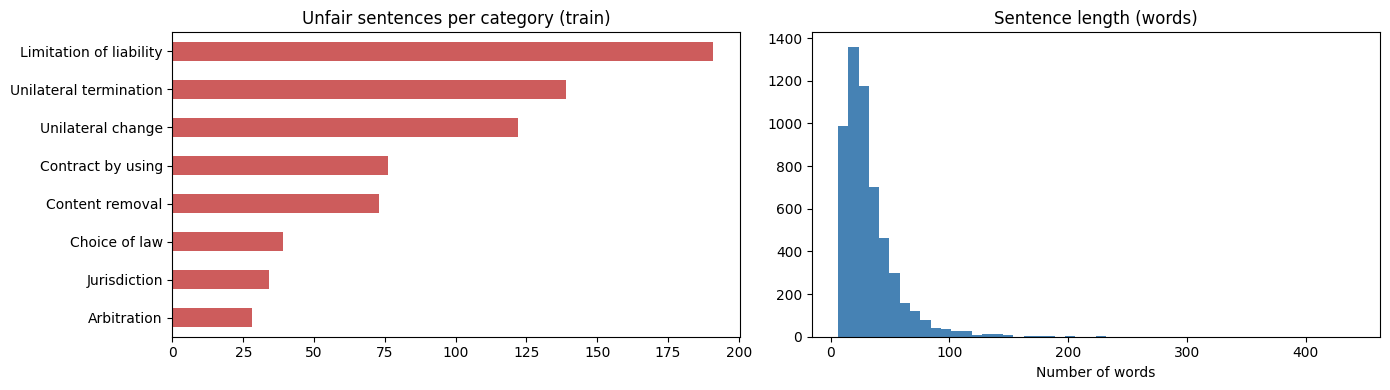


Sentence length: mean = 32.3 | 95% of sentences have ≤ 75 words


In [ ]:
# ============================================
# 3: Explore the data
# ============================================

for split in ["train", "validation", "test"]:
    df_split = dataset[split].to_pandas()
    n_total = len(df_split)
    n_unfair = (df_split["labels"].apply(len) > 0).sum()
    print(f"{split:<11} total: {n_total:>5} | unfair: {n_unfair:>4} ({n_unfair / n_total:.1%})")

train_df = dataset["train"].to_pandas()

label_counts = pd.Series(
    [label_names[j] for labels in train_df["labels"] for j in labels]
).value_counts()

print("\nUnfair sentences per category (train):")
print(label_counts)

print("\nSentences with more than one label:", (train_df["labels"].apply(len) > 1).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

label_counts.plot(kind="barh", ax=axes[0], color="indianred")
axes[0].set_title("Unfair sentences per category (train)")
axes[0].invert_yaxis()

train_df["n_words"] = train_df["text"].str.split().apply(len)
axes[1].hist(train_df["n_words"], bins=50, color="steelblue")
axes[1].set_title("Sentence length (words)")
axes[1].set_xlabel("Number of words")

plt.tight_layout()
plt.show()

print("\nSentence length: mean =", round(train_df["n_words"].mean(), 1),
      "| 95% of sentences have ≤", int(train_df["n_words"].quantile(0.95)), "words")

In [ ]:
# ============================================
# 4: Prepare the labels (convert to multi-label format)
# ============================================

def to_multi_hot(example):
    vec = [0.0] * NUM_LABELS
    for j in example["labels"]:
        vec[j] = 1.0
    example["label_vec"] = vec
    return example

dataset = dataset.map(to_multi_hot)

y_train = np.array(dataset["train"]["label_vec"])
y_val   = np.array(dataset["validation"]["label_vec"])
y_test  = np.array(dataset["test"]["label_vec"])

print("Shape (sentences, categories):", y_train.shape)

ex = dataset["train"].filter(lambda x: len(x["labels"]) > 0)[0]
print("\nExample text:", ex["text"])
print("Original labels:", ex["labels"], "→", [label_names[j] for j in ex["labels"]])
print("Multi-hot vector:", ex["label_vec"])
#changed the labels so they have the same shape as the model’s answers

Map:   0%|          | 0/5532 [00:00<?, ? examples/s]

Map:   0%|          | 0/1607 [00:00<?, ? examples/s]

Map:   0%|          | 0/2275 [00:00<?, ? examples/s]

Shape (sentences, categories): (5532, 8)


Filter:   0%|          | 0/5532 [00:00<?, ? examples/s]


Example text: by creating a tinder account or by using the tinder imessage app ( `` tinder stacks '' ) , whether through a mobile device , mobile application or computer ( collectively , the `` service '' ) you agree to be bound by ( i ) these terms of use , ( ii ) our privacy policy and safety tips , each of which is incorporated by reference into this agreement , and ( iii ) any terms disclosed and agreed to by you if you purchase additional features , products or services we offer on the service ( collectively , this `` agreement '' ) . 

Original labels: [4] → ['Contract by using']
Multi-hot vector: [0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0]


In [ ]:
# ============================================
# 5: Baseline model (TF-IDF + Logistic Regression)
# ============================================

X_train_text = dataset["train"]["text"]
X_val_text   = dataset["validation"]["text"]
X_test_text  = dataset["test"]["text"]

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf   = tfidf.transform(X_val_text)
X_test_tfidf  = tfidf.transform(X_test_text)

baseline = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, class_weight="balanced", C=4.0)
)
baseline.fit(X_train_tfidf, y_train)

def scores(y_true, y_pred):
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

val_pred_base  = baseline.predict(X_val_tfidf)
test_pred_base = baseline.predict(X_test_tfidf)

results = {}
results["TF-IDF + LogReg"] = {
    "val":  scores(y_val, val_pred_base),
    "test": scores(y_test, test_pred_base),
}

print("Validation:", {k: round(v, 4) for k, v in results["TF-IDF + LogReg"]["val"].items()})
print("Test:      ", {k: round(v, 4) for k, v in results["TF-IDF + LogReg"]["test"].items()})

print("\nPer-category report (test):")
print(classification_report(y_test, test_pred_base, target_names=label_names, zero_division=0))

Validation: {'micro_f1': 0.649, 'macro_f1': 0.6502}
Test:       {'micro_f1': 0.72, 'macro_f1': 0.7431}

Per-category report (test):
                         precision    recall  f1-score   support

Limitation of liability       0.63      0.82      0.71        38
 Unilateral termination       0.62      0.87      0.73        38
      Unilateral change       0.60      0.71      0.65        38
        Content removal       0.44      0.92      0.60        13
      Contract by using       0.73      0.83      0.78        23
          Choice of law       0.80      0.92      0.86        13
           Jurisdiction       0.86      0.75      0.80        16
            Arbitration       0.70      1.00      0.82         7

              micro avg       0.64      0.82      0.72       186
              macro avg       0.67      0.85      0.74       186
           weighted avg       0.66      0.82      0.72       186
            samples avg       0.08      0.09      0.08       186



**Insight** : The TF-IDF baseline reaches micro-F1 = 0.72 and macro-F1 = 0.74 on the test set. It finds most unfair clauses (recall 0.82) but gives many false alarms (precision 0.64), especially for Content removal. A transformer should reduce these false alarms by understanding meaning, not just words.

In [ ]:
# ============================================
# 6: Tokenize the text
# ============================================

MODELS = {
    "Legal-BERT": "nlpaueb/legal-bert-base-uncased",
    "RoBERTa":    "roberta-base",
    "DeBERTa-v3": "microsoft/deberta-v3-base",
}

MAX_LENGTH = 128

def tokenize_for(model_id):
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    def tok(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

    tokenized = dataset.map(tok, batched=True)
    tokenized = tokenized.remove_columns(["labels"]).rename_column("label_vec", "labels")
    tokenized = tokenized.remove_columns(["text"])
    return tokenizer, tokenized

# Quick check with one model
tokenizer, tokenized = tokenize_for(MODELS["Legal-BERT"])
print(tokenized)

sample = dataset["train"][0]["text"]
ids = tokenizer(sample)["input_ids"]
print("\nText:   ", sample)
print("Tokens: ", tokenizer.convert_ids_to_tokens(ids))
print("IDs:    ", ids)

lengths = [len(x) for x in tokenized["train"]["input_ids"]]
print(f"\nToken length: mean = {np.mean(lengths):.1f} | max = {max(lengths)} | "
      f"cut at {MAX_LENGTH}: {np.mean(np.array(lengths) >= MAX_LENGTH):.2%} of sentences")

config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/222k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/5532 [00:00<?, ? examples/s]

Map:   0%|          | 0/1607 [00:00<?, ? examples/s]

Map:   0%|          | 0/2275 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5532
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1607
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2275
    })
})

Text:    notice to california subscribers : you may cancel your subscription , without penalty or obligation , at any time prior to midnight of the third business day following the date you subscribed . 

Tokens:  ['[CLS]', 'notice', 'to', 'california', 'subscribers', ':', 'you', 'may', 'cancel', 'your', 'subscription', ',', 'without', 'penalty', 'or', 'obligation', ',', 'at', 'any', 'time', 'prior', 'to', 'mid', '##night', 'of', 'the', 'third', 'business', 'day', 'following', 'the', 'date', 'you', 'subscribed', '.', '[SEP]']
IDs:     [101, 326, 211, 2015, 7492, 119, 799, 245, 3697

In [ ]:
# ============================================
# 7: Define the metrics (micro-F1, macro-F1)
# ============================================

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def compute_metrics(eval_pred, threshold=0.5):
    logits, labels = eval_pred
    probs = sigmoid(logits)
    preds = (probs >= threshold).astype(int)
    labels = labels.astype(int)
    return {
        "micro_f1":  f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1":  f1_score(labels, preds, average="macro", zero_division=0),
        "precision": precision_score(labels, preds, average="micro", zero_division=0),
        "recall":    recall_score(labels, preds, average="micro", zero_division=0),
    }

# Quick test with fake numbers
fake_logits = np.array([[3.0, -2.0, -1.0, -3.0, -2.0, -4.0, -1.0, -2.0],
                        [-3.0, -2.0, -1.0, -3.0, -2.0, -4.0, -1.0, -2.0]])
fake_labels = np.array([[1, 0, 0, 0, 0, 0, 0, 0],
                        [0, 0, 0, 0, 0, 0, 0, 0]])
print(compute_metrics((fake_logits, fake_labels)))

{'micro_f1': 1.0, 'macro_f1': 0.125, 'precision': 1.0, 'recall': 1.0}


In [ ]:
# ============================================
# 8: Define the weighted loss (to handle class imbalance)
# ============================================

pos_counts = y_train.sum(axis=0)
neg_counts = len(y_train) - pos_counts

# sqrt softens the weights so the model doesn't over-warn
pos_weight = np.sqrt(neg_counts / pos_counts)
pos_weight_tensor = torch.tensor(pos_weight, dtype=torch.float)

print(pd.DataFrame({
    "category": label_names,
    "unfair_count": pos_counts.astype(int),
    "weight": pos_weight.round(2),
}).to_string(index=False))

class WeightedTrainer(Trainer):
    def __init__(self, *args, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        if self.pos_weight is not None:
            loss_fn = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(logits.device))
        else:
            loss_fn = nn.BCEWithLogitsLoss()

        loss = loss_fn(logits, labels.float())
        return (loss, outputs) if return_outputs else loss

               category  unfair_count  weight
Limitation of liability           191    5.29
 Unilateral termination           139    6.23
      Unilateral change           122    6.66
        Content removal            73    8.65
      Contract by using            76    8.47
          Choice of law            39   11.87
           Jurisdiction            34   12.72
            Arbitration            28   14.02


In [ ]:
# ============================================
# Step 9: Training function (one function for all models)
# ============================================

def train_model(name, model_id, use_weights=True, epochs=5, lr=2e-5, batch_size=16):
    run_name = f"{name}_{'weighted' if use_weights else 'plain'}"
    print(f"\n{'=' * 50}\nTraining: {run_name}\n{'=' * 50}")

    tokenizer, tokenized = tokenize_for(model_id)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=NUM_LABELS,
        problem_type="multi_label_classification",
        id2label={i: n for i, n in enumerate(label_names)},
        label2id={n: i for i, n in enumerate(label_names)},
        dtype=torch.float32,   # load full precision; fp16 is applied only during training
    )

    total_steps = int(np.ceil(len(tokenized["train"]) / batch_size)) * epochs
    warmup_steps = int(0.1 * total_steps)

    args = TrainingArguments(
        output_dir=f"/content/runs/{run_name}",   # temporary checkpoints (not Drive)
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epochs,
        weight_decay=0.01,
        warmup_steps=warmup_steps,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        fp16=torch.cuda.is_available(),
        logging_steps=50,
        report_to="none",
        seed=SEED,
    )

    trainer = WeightedTrainer(
        model=model,
        args=args,
        train_dataset=tokenized["train"],
        eval_dataset=tokenized["validation"],
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
        pos_weight=pos_weight_tensor if use_weights else None,
    )

    start = time.time()
    trainer.train()
    train_minutes = (time.time() - start) / 60

    val_logits  = trainer.predict(tokenized["validation"]).predictions
    test_logits = trainer.predict(tokenized["test"]).predictions

    # Save best model + predictions to Drive
    run_dir = f"{SAVE_DIR}/{run_name}"
    trainer.save_model(run_dir)
    tokenizer.save_pretrained(run_dir)
    np.save(f"{run_dir}/val_logits.npy", val_logits)
    np.save(f"{run_dir}/test_logits.npy", test_logits)

    val_scores  = compute_metrics((val_logits, y_val))
    test_scores = compute_metrics((test_logits, y_test))
    print(f"\n{run_name} | time: {train_minutes:.1f} min")
    print("Validation:", {k: round(v, 4) for k, v in val_scores.items()})
    print("Test:      ", {k: round(v, 4) for k, v in test_scores.items()})

    del model, trainer
    torch.cuda.empty_cache()

    return {
        "val": val_scores,
        "test": test_scores,
        "val_logits": val_logits,
        "test_logits": test_logits,
        "minutes": train_minutes,
    }

In [ ]:
# ============================================
# 10: Train & compare 3 models (Legal-BERT, RoBERTa, DeBERTa)
# ============================================

EXPERIMENTS = [
    ("Legal-BERT", True),
    ("RoBERTa",    True),
    ("DeBERTa-v3", True),
    ("Legal-BERT", False),
    ("RoBERTa",    False),
    ("DeBERTa-v3", False),
]

all_runs = {}

for name, use_weights in EXPERIMENTS:
    run_name = f"{name}_{'weighted' if use_weights else 'plain'}"
    run_dir = f"{SAVE_DIR}/{run_name}"

    # Skip runs already saved in Drive (if Colab disconnected)
    if os.path.exists(f"{run_dir}/test_logits.npy"):
        print(f"Loading saved run: {run_name}")
        val_logits  = np.load(f"{run_dir}/val_logits.npy")
        test_logits = np.load(f"{run_dir}/test_logits.npy")
        all_runs[run_name] = {
            "val": compute_metrics((val_logits, y_val)),
            "test": compute_metrics((test_logits, y_test)),
            "val_logits": val_logits,
            "test_logits": test_logits,
            "minutes": None,
        }
        continue

    all_runs[run_name] = train_model(name, MODELS[name], use_weights=use_weights)

rows = []
for run_name, r in all_runs.items():
    rows.append({
        "model": run_name,
        "val_macro_f1":  r["val"]["macro_f1"],
        "test_micro_f1": r["test"]["micro_f1"],
        "test_macro_f1": r["test"]["macro_f1"],
        "test_precision": r["test"]["precision"],
        "test_recall":   r["test"]["recall"],
        "minutes": r["minutes"],
    })

base = results["TF-IDF + LogReg"]["test"]
rows.append({"model": "TF-IDF + LogReg (baseline)",
             "val_macro_f1": results["TF-IDF + LogReg"]["val"]["macro_f1"],
             "test_micro_f1": base["micro_f1"], "test_macro_f1": base["macro_f1"],
             "test_precision": None, "test_recall": None, "minutes": None})

comparison = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False).round(4)
comparison.to_csv(f"{SAVE_DIR}/comparison_threshold_0.5.csv", index=False)
comparison

Loading saved run: Legal-BERT_weighted
Loading saved run: RoBERTa_weighted
Loading saved run: DeBERTa-v3_weighted
Loading saved run: Legal-BERT_plain
Loading saved run: RoBERTa_plain
Loading saved run: DeBERTa-v3_plain


,model,val_macro_f1,test_micro_f1,test_macro_f1,test_precision,test_recall,minutes
4,RoBERTa_plain,0.7485,0.7853,0.8065,0.7653,0.8065,None
1,RoBERTa_weighted,0.7153,0.7476,0.7440,0.6814,0.8280,None
3,Legal-BERT_plain,0.6910,0.7966,0.8173,0.8393,0.7581,None
0,Legal-BERT_weighted,0.6898,0.7395,0.7545,0.6516,0.8548,None
6,TF-IDF + LogReg (baseline),0.6502,0.7200,0.7431,NaN,NaN,None
2,DeBERTa-v3_weighted,0.6029,0.6543,0.6454,0.5300,0.8548,None
5,DeBERTa-v3_plain,0.4973,0.6706,0.5300,0.7403,0.6129,None


In [ ]:
# ============================================
# 11: Tune thresholds for each category
# ============================================

THRESHOLD_GRID = np.arange(0.05, 0.96, 0.05)

def tune_thresholds(val_logits, y_true):
    probs = sigmoid(val_logits)
    best = np.zeros(NUM_LABELS)
    for j in range(NUM_LABELS):
        f1s = [f1_score(y_true[:, j], (probs[:, j] >= t).astype(int), zero_division=0)
               for t in THRESHOLD_GRID]
        best[j] = THRESHOLD_GRID[int(np.argmax(f1s))]
    return best

def scores_with_thresholds(logits, y_true, thresholds):
    preds = (sigmoid(logits) >= thresholds).astype(int)
    y_true = y_true.astype(int)
    return {
        "micro_f1":  f1_score(y_true, preds, average="micro", zero_division=0),
        "macro_f1":  f1_score(y_true, preds, average="macro", zero_division=0),
        "precision": precision_score(y_true, preds, average="micro", zero_division=0),
        "recall":    recall_score(y_true, preds, average="micro", zero_division=0),
    }

rows = []
for run_name, r in all_runs.items():
    th = tune_thresholds(r["val_logits"], y_val)
    r["thresholds"] = th
    r["val_tuned"]  = scores_with_thresholds(r["val_logits"], y_val, th)
    r["test_tuned"] = scores_with_thresholds(r["test_logits"], y_test, th)
    rows.append({
        "model": run_name,
        "val_macro_f1 (0.5)":   r["val"]["macro_f1"],
        "val_macro_f1 (tuned)": r["val_tuned"]["macro_f1"],
        "test_micro_f1 (tuned)": r["test_tuned"]["micro_f1"],
        "test_macro_f1 (tuned)": r["test_tuned"]["macro_f1"],
        "test_precision (tuned)": r["test_tuned"]["precision"],
        "test_recall (tuned)":   r["test_tuned"]["recall"],
    })

tuned_table = pd.DataFrame(rows).sort_values("val_macro_f1 (tuned)", ascending=False).round(4)
tuned_table.to_csv(f"{SAVE_DIR}/comparison_tuned.csv", index=False)

BEST_RUN = tuned_table.iloc[0]["model"]
best_th = all_runs[BEST_RUN]["thresholds"]

print("Best model (by validation):", BEST_RUN)
print("\nThresholds per category:")
for name, t in zip(label_names, best_th):
    print(f"  {name:<25} {t:.2f}")

with open(f"{SAVE_DIR}/{BEST_RUN}/thresholds.json", "w") as f:
    json.dump({n: float(t) for n, t in zip(label_names, best_th)}, f, indent=2)

tuned_table

Best model (by validation): RoBERTa_plain

Thresholds per category:
  Limitation of liability   0.45
  Unilateral termination    0.35
  Unilateral change         0.50
  Content removal           0.55
  Contract by using         0.90
  Choice of law             0.35
  Jurisdiction              0.50
  Arbitration               0.45


,model,val_macro_f1 (0.5),val_macro_f1 (tuned),test_micro_f1 (tuned),test_macro_f1 (tuned),test_precision (tuned),test_recall (tuned)
4,RoBERTa_plain,0.7485,0.7777,0.7546,0.7749,0.7409,0.7688
3,Legal-BERT_plain,0.6910,0.7696,0.7875,0.8101,0.8323,0.7473
0,Legal-BERT_weighted,0.6898,0.7619,0.7467,0.7547,0.7259,0.7688
1,RoBERTa_weighted,0.7153,0.7555,0.7551,0.7506,0.7184,0.7957
2,DeBERTa-v3_weighted,0.6029,0.7496,0.7390,0.7516,0.7114,0.7688
5,DeBERTa-v3_plain,0.4973,0.6636,0.6763,0.6620,0.7312,0.6290


**Insight:** Once the cutoffs were tuned, the weighted loss no longer showed a clear advantage over the plain loss. For RoBERTa and Legal-BERT, test scores dropped slightly after tuning. This suggests the cutoffs overfit the validation set, since some categories have only a few validation sentences. Legal-BERT_plain reached the highest test precision (0.83), which means the fewest false alarms. However, we do not choose it based on test results, because using the test set to pick a model would make the final score unfair. Following our rule of selecting by validation, the winner is **RoBERTa_plain** (validation macro-F1 = 0.778).

Final model: RoBERTa_plain (tuned thresholds)

                         precision    recall  f1-score   support

Limitation of liability      0.667     0.789     0.723        38
 Unilateral termination      0.696     0.842     0.762        38
      Unilateral change      0.730     0.711     0.720        38
        Content removal      0.647     0.846     0.733        13
      Contract by using      1.000     0.435     0.606        23
          Choice of law      0.857     0.923     0.889        13
           Jurisdiction      0.882     0.938     0.909        16
            Arbitration      0.857     0.857     0.857         7

              micro avg      0.741     0.769     0.755       186
              macro avg      0.792     0.793     0.775       186
           weighted avg      0.764     0.769     0.749       186
            samples avg      0.082     0.083     0.081       186

               category  test_sentences  threshold  precision  recall    f1
           Jurisdiction      

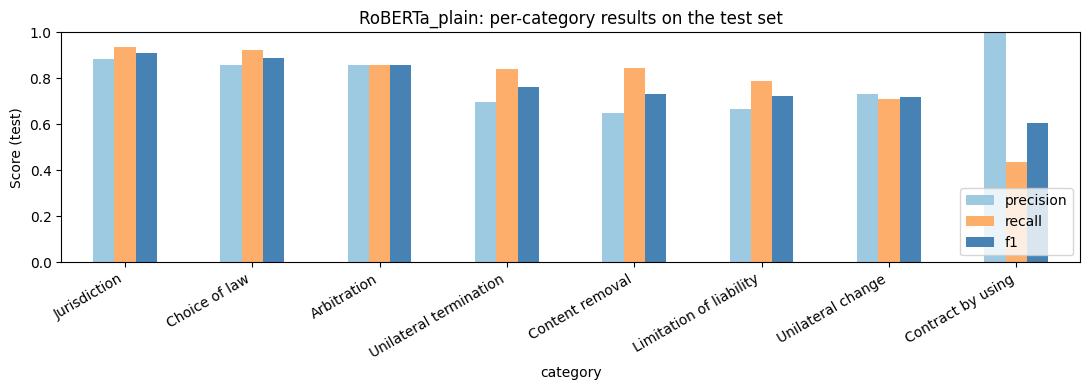

In [ ]:
# ============================================
# 12: Final evaluation on the test set
# ============================================

best = all_runs[BEST_RUN]
test_probs = sigmoid(best["test_logits"])
test_pred_best = (test_probs >= best_th).astype(int)
y_test_int = y_test.astype(int)

#Macro answers “Is the model good at all categories, including the rare ones?” (Compute F1 for each category separately, then take the simple average of the 8 numbers.)
#Micro answers : “Overall, how good are the model’s warnings?” (Put all predictions from all categories together in one big pile.)

print(f"Final model: {BEST_RUN} (tuned thresholds)\n")
print(classification_report(y_test_int, test_pred_best,
                            target_names=label_names, zero_division=0, digits=3))

per_cat = pd.DataFrame({
    "category":       label_names,
    "test_sentences": y_test_int.sum(axis=0),
    "threshold":      best_th,
    "precision":      precision_score(y_test_int, test_pred_best, average=None, zero_division=0),
    "recall":         recall_score(y_test_int, test_pred_best, average=None, zero_division=0),
    "f1":             f1_score(y_test_int, test_pred_best, average=None, zero_division=0),
}).round(3).sort_values("f1", ascending=False)
per_cat.to_csv(f"{SAVE_DIR}/{BEST_RUN}/per_category_test.csv", index=False)
print(per_cat.to_string(index=False))

print("\nOverall (test):", {k: round(v, 4) for k, v in best["test_tuned"].items()})

plot_df = per_cat.set_index("category")[["precision", "recall", "f1"]]
plot_df.plot(kind="bar", figsize=(11, 4), color=["#9ecae1", "#fdae6b", "steelblue"])
plt.ylim(0, 1)
plt.ylabel("Score (test)")
plt.title(f"{BEST_RUN}: per-category results on the test set")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/{BEST_RUN}/per_category_test.png", dpi=150)
plt.show()

**Insight:** The final model (RoBERTa_plain, tuned) reaches test micro-F1 = 0.755 and macro-F1 = 0.775, with balanced precision (0.74) and recall (0.77).

It performs best on categories with fixed legal phrasing (Jurisdiction, Choice of law, Arbitration: F1 0.86–0.91), although these have few test sentences.

Categories with more varied and overlapping wording (termination, content removal, liability, change) are harder (F1 0.72–0.76) and cause most false alarms.

 *Contract by using* is the weakest (F1 0.61): its strict 0.90 cutoff, tuned on the small validation set, gives perfect precision but misses more than half of the cases, a clear sign of threshold overfitting.

In [ ]:
# ============================================
# Step 13: Error analysis
# ============================================

test_texts = dataset["test"]["text"]

#This step is because scores tell you how much the model is wrong, Examples tell you why.

def names(vec):
    return [label_names[j] for j in np.where(vec == 1)[0]] or ["fair"]

rows = []
for i in range(len(test_texts)):
    true_v, pred_v = y_test_int[i], test_pred_best[i]
    if (true_v == pred_v).all():
        continue
    if true_v.sum() == 0:
        kind = "False alarm (fair → flagged)"
    elif pred_v.sum() == 0:
        kind = "Missed (unfair → fair)"
    elif (true_v & pred_v).sum() > 0:
        kind = "Partly correct (≥1 right category)"
    else:
        kind = "Completely wrong category"
    rows.append({
        "type": kind,
        "true": ", ".join(names(true_v)),
        "predicted": ", ".join(names(pred_v)),
        "max_prob": round(float(test_probs[i].max()), 2),
        "text": test_texts[i],
    })

errors = pd.DataFrame(rows)
errors.to_csv(f"{SAVE_DIR}/{BEST_RUN}/errors_test.csv", index=False)

print(f"Total test sentences: {len(test_texts)} | sentences with errors: {len(errors)}\n")
print(errors["type"].value_counts(), "\n")

pd.set_option("display.max_colwidth", 200)

for kind in errors["type"].unique():
    print(f"\n{'=' * 70}\n{kind}\n{'=' * 70}")
    sample = errors[errors["type"] == kind].sort_values("max_prob", ascending=False).head(4)
    for _, r in sample.iterrows():
        print(f"- TRUE: {r['true']} | PRED: {r['predicted']} | prob: {r['max_prob']}")
        print(f"  {r['text'][:250]}\n")

print(f"\n{'=' * 70}\nMissed 'Contract by using' examples\n{'=' * 70}")
cbu = label_names.index("Contract by using")
missed_cbu = np.where((y_test_int[:, cbu] == 1) & (test_pred_best[:, cbu] == 0))[0]
for i in missed_cbu[:4]:
    print(f"- prob: {test_probs[i, cbu]:.2f} (cutoff {best_th[cbu]:.2f})")
    print(f"  {test_texts[i][:250]}\n")

Total test sentences: 1607 | sentences with errors: 86

type
False alarm (fair → flagged)          32
Missed (unfair → fair)                32
Partly correct (≥1 right category)    20
Completely wrong category              2
Name: count, dtype: int64 


Partly correct (≥1 right category)
- TRUE: Unilateral termination, Unilateral change | PRED: Unilateral change | prob: 0.92
  we may change , suspend or end any service , or change and modify prices prospectively in our discretion . 


- TRUE: Unilateral termination, Unilateral change | PRED: Unilateral termination | prob: 0.91
  linkedin reserves the right to restrict , suspend , or terminate your account if linkedin believes that you may be in breach of this contract or law or are misusing the services ( e.g. violating any do and do n'ts ) . 


- TRUE: Unilateral termination | PRED: Unilateral termination, Content removal | prob: 0.9
  we may suspend or terminate your account or cease providing you with all or part of the services at 

**Insight:** Of the 22 wrong-category errors, 20 are partly correct and only 2 are completely wrong, so the model rarely confuses unrelated categories.

 The most important finding is in the missed clauses: several *Contract by using* sentences were predicted with probabilities of 0.87–0.89, just below the strict 0.90 cutoff.

  This confirms that the cutoff tuned on the small validation set is too strict.
  
  When "by using…" appears only as a side phrase in a sentence about another topic, the model gives it a very low probability.
  
  Many false alarms contain alarming words ("terminate," "not liable") but were judged fair because of their conditions, e.g. account closure to prevent fraud, or liability limited to the user's own fault.
  
   This shows the model has learned the typical vocabulary of unfair clauses but not the legal reasoning about when a clause is justified.
   
   The 2 fully wrong cases both mix "change" with "discontinue/eliminate," where the word "change" pulls the model toward *Unilateral change*.

In [ ]:
# ============================================
# Step 14: Save the best model (Drive + Hugging Face Hub)
# ============================================

import shutil
from huggingface_hub import notebook_login, HfApi

FINAL_DIR = f"{SAVE_DIR}/final_model"
best_dir  = f"{SAVE_DIR}/{BEST_RUN}"

if os.path.exists(FINAL_DIR):
    shutil.rmtree(FINAL_DIR)
shutil.copytree(best_dir, FINAL_DIR, ignore=shutil.ignore_patterns("*.npy", "*.csv", "*.png"))

# App thresholds: Contract by using lowered after error analysis
app_th = {n: float(t) for n, t in zip(label_names, best_th)}
app_th["Contract by using"] = 0.5

with open(f"{FINAL_DIR}/thresholds.json", "w") as f:
    json.dump({n: float(t) for n, t in zip(label_names, best_th)}, f, indent=2)
with open(f"{FINAL_DIR}/app_thresholds.json", "w") as f:
    json.dump(app_th, f, indent=2)

print("Saved to Drive:", FINAL_DIR)
print(os.listdir(FINAL_DIR))

check_tok = AutoTokenizer.from_pretrained(FINAL_DIR)
check_model = AutoModelForSequenceClassification.from_pretrained(FINAL_DIR).eval()
s = "we may terminate your account at any time without notice ."
with torch.no_grad():
    p = torch.sigmoid(check_model(**check_tok(s, return_tensors="pt")).logits)[0].numpy()
print("\nTest sentence:", s)
for n, v in sorted(zip(label_names, p), key=lambda x: -x[1])[:3]:
    print(f"  {n:<25} {v:.2f}")

Saved to Drive: /content/drive/MyDrive/policy_reader/final_model
['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_args.bin', 'thresholds.json', 'app_thresholds.json']


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Test sentence: we may terminate your account at any time without notice .
  Unilateral termination    0.84
  Content removal           0.14
  Limitation of liability   0.08


In [ ]:
# ============================================
# Step 14b: Upload the model to Hugging Face Hub
# ============================================

notebook_login()

HF_REPO = "policy-reader-roberta"

check_model.push_to_hub(HF_REPO)
check_tok.push_to_hub(HF_REPO)

api = HfApi()
user = api.whoami()["name"]
for fname in ["thresholds.json", "app_thresholds.json"]:
    api.upload_file(path_or_fileobj=f"{FINAL_DIR}/{fname}", path_in_repo=fname,
                    repo_id=f"{user}/{HF_REPO}")

print(f"Model uploaded: https://huggingface.co/{user}/{HF_REPO}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._3tpe_q/model.safetensors:   2%|1         | 7.93MB /  499MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


Model uploaded: https://huggingface.co/LayanSh1/policy-reader-roberta


In [ ]:
# ============================================
# Step 14c: Convert to ONNX + quantize (for the browser app)
# ============================================

!pip install -q onnx onnxruntime

import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType

ONNX_DIR = f"{SAVE_DIR}/onnx"
os.makedirs(ONNX_DIR, exist_ok=True)
fp32_path  = f"{ONNX_DIR}/model.onnx"
quant_path = f"{ONNX_DIR}/model_quantized.onnx"

class LogitsOnly(nn.Module):
    def __init__(self, m):
        super().__init__()
        self.m = m
    def forward(self, input_ids, attention_mask):
        return self.m(input_ids=input_ids, attention_mask=attention_mask).logits

export_model = LogitsOnly(check_model.float().eval())
dummy = check_tok(["a short example sentence ."], return_tensors="pt")

torch.onnx.export(
    export_model,
    (dummy["input_ids"], dummy["attention_mask"]),
    fp32_path,
    input_names=["input_ids", "attention_mask"],
    output_names=["logits"],
    dynamic_axes={"input_ids": {0: "batch", 1: "seq"},
                  "attention_mask": {0: "batch", 1: "seq"},
                  "logits": {0: "batch"}},
    opset_version=14,
    dynamo=False,
)

quantize_dynamic(fp32_path, quant_path, weight_type=QuantType.QUInt8)

size_mb = lambda p: os.path.getsize(p) / 1e6
print(f"Original ONNX: {size_mb(fp32_path):.0f} MB | Quantized: {size_mb(quant_path):.0f} MB")

def onnx_test_logits(path, batch_size=64):
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    out = []
    for i in range(0, len(X_test_text), batch_size):
        enc = check_tok(X_test_text[i:i + batch_size], truncation=True,
                        max_length=MAX_LENGTH, padding=True, return_tensors="np")
        out.append(sess.run(["logits"], {"input_ids": enc["input_ids"].astype(np.int64),
                                         "attention_mask": enc["attention_mask"].astype(np.int64)})[0])
    return np.concatenate(out)

pt_scores    = all_runs[BEST_RUN]["test_tuned"]
fp32_scores  = scores_with_thresholds(onnx_test_logits(fp32_path),  y_test, best_th)
quant_scores = scores_with_thresholds(onnx_test_logits(quant_path), y_test, best_th)

quant_table = pd.DataFrame([
    {"version": "PyTorch (original)", "size_MB": None, **pt_scores},
    {"version": "ONNX fp32",          "size_MB": size_mb(fp32_path),  **fp32_scores},
    {"version": "ONNX quantized int8", "size_MB": size_mb(quant_path), **quant_scores},
]).round(4)
quant_table.to_csv(f"{SAVE_DIR}/quantization_results.csv", index=False)
quant_table

Original ONNX: 499 MB | Quantized: 126 MB


,version,size_MB,micro_f1,macro_f1,precision,recall
0,PyTorch (original),NaN,0.7546,0.7749,0.7409,0.7688
1,ONNX fp32,498.8925,0.7546,0.7749,0.7409,0.7688
2,ONNX quantized int8,125.5195,0.7507,0.7617,0.7487,0.7527


In [ ]:
# ============================================
# Step 14d: Upload the quantized model for the website
# ============================================

api.upload_file(path_or_fileobj=quant_path, path_in_repo="onnx/model_quantized.onnx",
                repo_id=f"{user}/{HF_REPO}")

files = api.list_repo_files(f"{user}/{HF_REPO}")
print("Files in repo:")
for f in files:
    print("  ", f)

needed = ["config.json", "tokenizer.json", "onnx/model_quantized.onnx", "app_thresholds.json"]
missing = [f for f in needed if f not in files]
print("\nReady for the website ✅" if not missing else f"\nMissing: {missing}")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...onnx/model_quantized.onnx:   4%|4         | 5.27MB /  126MB            

Validating                    :           |   0%            

Files in repo:
   .gitattributes
   README.md
   app_thresholds.json
   config.json
   model.safetensors
   onnx/model_quantized.onnx
   thresholds.json
   tokenizer.json
   tokenizer_config.json

Ready for the website ✅
